# SunSCC — Pseudo-label playground

Starter notebook for segment-related testing/experimentation **without touching the CLI**.
Everything is importable from the `sunscc` package (installed editable in the project venv).

Typical uses:
- calibrate pseudo-label generation on new images (footprint size, thresholds)
- inspect patches exactly as the training `Dataset` serves them
- compare masks, e.g. two thresholds with the paper's detection metrics
- smoke-test the model / visualize a checkpoint's predictions

Run either locally (`uv run jupyter lab`) or in docker (jupyter lab, `/work` = repo root).

In [11]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

from sunscc import pseudolabels as pl
from sunscc.dataset import GRID, PATCH_SIZE, load_fits_patch, patch_grid_offsets
from sunscc.metrics import DetectionF1Accumulator
from sunscc.unet import build_paper_unet

plt.rcParams["figure.dpi"] = 100

## 0. EDIT ME — input paths

Point these wherever your mirror or sample data lives.

In [12]:
EXAMPLE_FITS = Path("/tmp/opencode/UPH20130101133418.FTS")   # sample from SIDC L1c WL 2013/01
OUT_DIR = Path("notebook_outputs")
OUT_DIR.mkdir(exist_ok=True)
assert EXAMPLE_FITS.exists(), f"no such file: {EXAMPLE_FITS} - edit the path above"
EXAMPLE_FITS

PosixPath('/tmp/opencode/UPH20130101133418.FTS')

## 1. Load image + solar-disk geometry

`SOLAR_R` comes from the FITS header (falls back to a half-max estimate for
headers that lack it).

UPH20130101133418.FTS: SOLAR_R = 977.9px, quiet-sun median = 2447


Text(0.5, 1.0, 'UPH20130101133418.FTS')

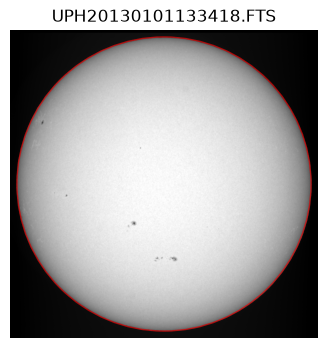

In [13]:
image = pl.load_wl_image(EXAMPLE_FITS)
center_y, center_x, radius = pl.read_solar_disk_geometry(EXAMPLE_FITS, image)
disk = pl.solar_disk_mask(image.shape, center_y, center_x, radius)

qs = image[image > 0]
print(f"{EXAMPLE_FITS.name}: SOLAR_R = {radius:.1f}px, quiet-sun median = {np.median(qs):.0f}")

fig, ax = plt.subplots(figsize=(4, 4))
vmin, vmax = np.percentile(qs, [1, 99.9])
ax.imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
ax.add_patch(plt.Circle((center_x, center_y), radius, fill=False, color="r", alpha=.6))
ax.set_axis_off()
ax.set_title(EXAMPLE_FITS.name)

## 2. Limb darkening correction

Radial intensity profile (azimuthal mean) gets a sigma-clipped polynomial fit;
dividing by it flattens the disk. Used **only** for pseudo-label generation -
the CNN itself sees the RAW image (paper sec. 4.2.2).

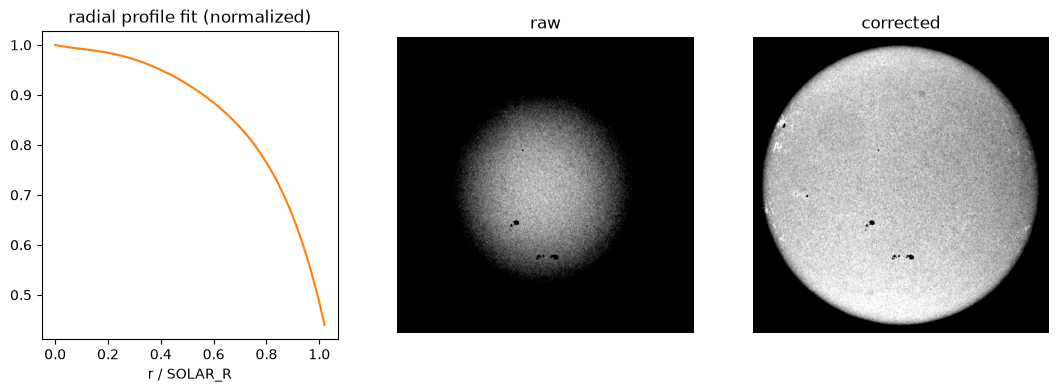

In [14]:
profile_of_r, central = pl.fit_limb_darkening_profile(image, center_y, center_x, radius)
corrected = pl.limb_darkening_correct(image, center_y, center_x, radius)

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
rs = np.linspace(0, 1.02, 300)
axs[0].plot(rs, [profile_of_r(r) for r in rs], color="tab:orange")
axs[0].set_title("radial profile fit (normalized)")
axs[0].set_xlabel("r / SOLAR_R")
cmin, cmax = np.percentile(corrected[disk], [2, 98])
for ax, img, title in ((axs[1], image, "raw"), (axs[2], corrected, "corrected")):
    ax.imshow(img, cmap="gray", vmin=cmin, vmax=cmax)
    ax.set_axis_off()
    ax.set_title(title)

## 3. Black top-hat (dark-structure contrast)

Uses OpenCV MORPH_CLOSE with an elliptical SE (`footprint_radius`) so that the
interior of whole sunspot groups is captured (skimage's disk SE is too slow for
the large footprints this needs). Threshold values live on the RAW intensity
scale - with USET L1c the paper's 250-500 sweep works directly.

Text(0.5, 0, 'top-hat value')

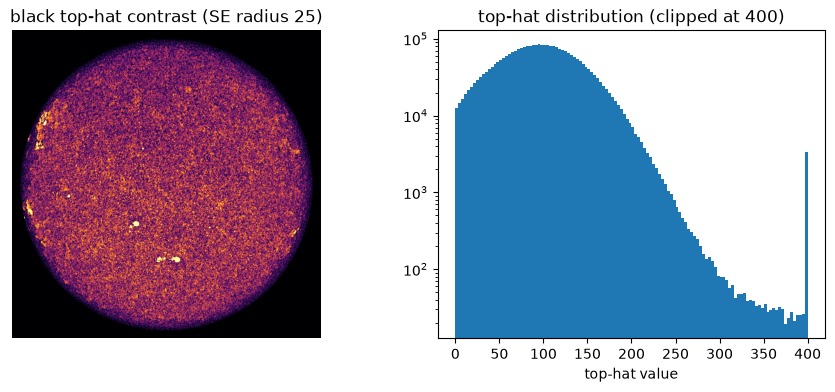

In [5]:
FOOTPRINT = pl.DEFAULT_FOOTPRINT_RADIUS   # EDIT ME when tuning (default 25 px)

tophat = pl.contrast_tophat(corrected, footprint_radius=FOOTPRINT, mask=disk)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].imshow(tophat, cmap="inferno", vmax=np.percentile(tophat, 99.8))
axs[0].set_axis_off()
axs[0].set_title(f"black top-hat contrast (SE radius {FOOTPRINT})")
vals = tophat[tophat > 0]
axs[1].hist(np.clip(vals, 0, 400), bins=120)
axs[1].set_yscale("log")
axs[1].set_title("top-hat distribution (clipped at 400)")
axs[1].set_xlabel("top-hat value")

## 4. Threshold sweep

Where does the fg fraction stop blowing up / spots vanish? The paper trains on
the 3 highlighted thresholds and sweeps 250-500 for experiments.

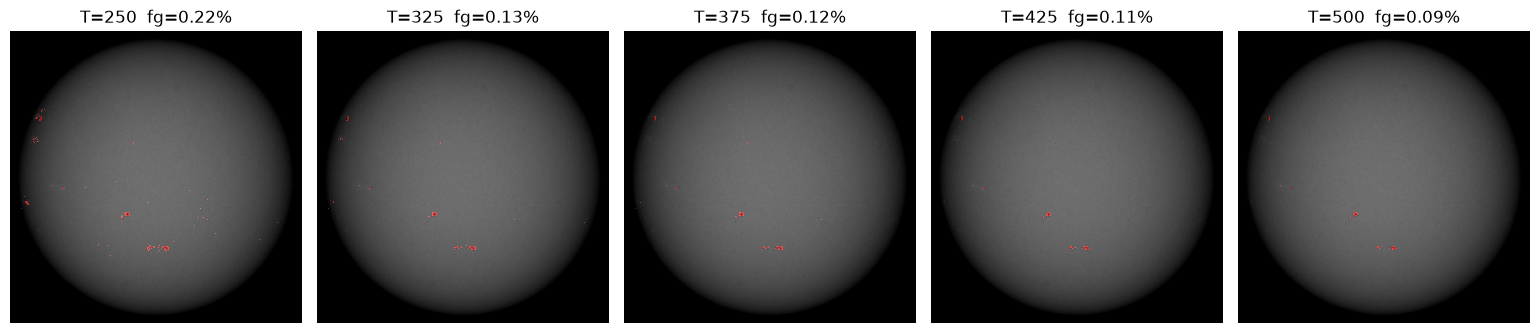

In [6]:
THRESHOLDS = [250.0, 325.0, 375.0, 425.0, 500.0]   # EDIT ME (or use pl.threshold_sweep())

def render_base(img):
    lo, hi = np.percentile(img[disk], [1, 99.9])
    return (np.clip((img - lo) / (hi - lo) * 255, 0, 255)).astype(np.uint8)

def show_overlay(ax, base_u8, mask, title=""):
    ax.imshow(base_u8, cmap="gray")
    rgb = np.zeros(mask.shape + (3,), np.uint8)
    rgb[mask] = (255, 30, 30)
    ax.imshow(rgb, alpha=0.55, interpolation="none")
    ax.set_axis_off()
    if title:
        ax.set_title(title)

base = render_base(image)
masks = {}
axs = plt.subplots(1, len(THRESHOLDS), figsize=(3.1 * len(THRESHOLDS), 3.4), sharey=True)[1]
for ax, t in zip(np.atleast_1d(axs), THRESHOLDS):
    m = pl.threshold_mask(tophat, threshold=t, min_area=pl.DEFAULT_MIN_DETECTION_AREA)
    masks[t] = m
    show_overlay(ax, base, m, f"T={int(t)}  fg={m[disk].mean() * 100:.2f}%")
plt.tight_layout()

## 5. The one-stop generator (filepath -> filepath)

Exactly what the `sunscc-generate-masks` CLI calls in a loop.

In [7]:
out_png = OUT_DIR / f"{EXAMPLE_FITS.stem}_T375.png"
pl.generate_pseudolabel(EXAMPLE_FITS, out_png, threshold=375.0, overwrite=True)
print("wrote:", out_png.resolve())

wrote: /home/x3nom/git/skvrna-ai/notebooks/notebook_outputs/UPH20130101133418_T375.png


## 6. Patches as the training Dataset serves them

4x4 grid of 512x512 raw patches (paper sec. 4.1). Same per-image normalization
as `PseudoLabelPatchDataset` (99.9th percentile).

normalization scale = 3375


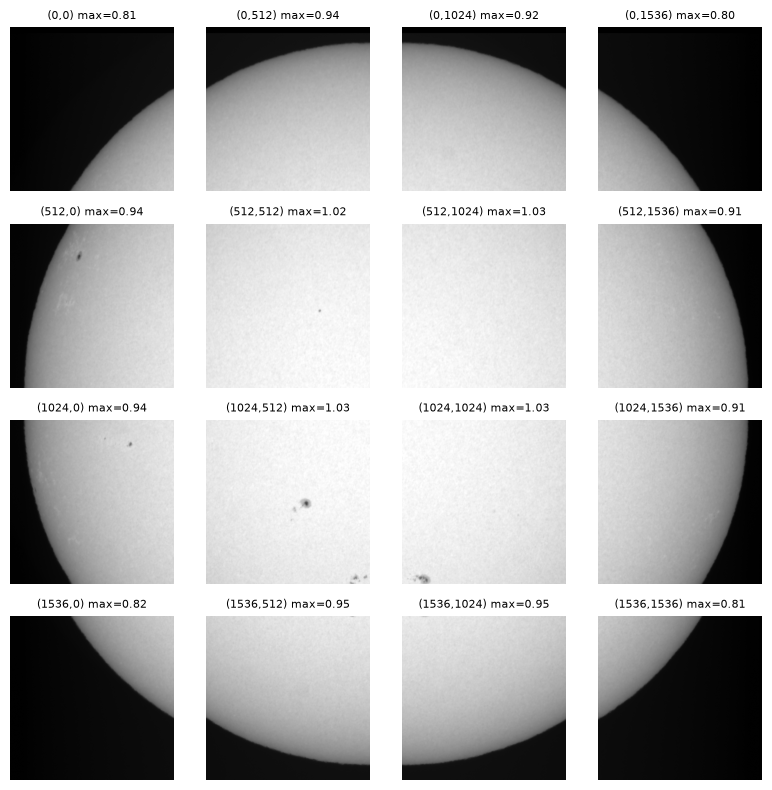

In [8]:
scale = np.percentile(image[image > 0], 99.9)     # == ImageScaleCache()(EXAMPLE_FITS)
print(f"normalization scale = {scale:.0f}")

fig, axs = plt.subplots(GRID, GRID, figsize=(8, 8))
for (r, c), ax in zip(patch_grid_offsets(), axs.ravel()):
    patch = load_fits_patch(EXAMPLE_FITS, r, c) / scale
    ax.imshow(patch, cmap="gray", vmin=0, vmax=1)
    ax.set_axis_off()
    ax.set_title(f"({r},{c}) max={patch.max():.2f}", fontsize=8)
plt.tight_layout()

## 7. Detection-F1 between two masks (consistency check)

How the paper scores masks: sunspot-level detection (connected components,
centroid matching, fusions). Here we compare two THRESHOLD masks against each
other to see how much they agree - the CNN-3 models must reconcile all three.

In [9]:
acc = DetectionF1Accumulator()
result = acc.update(masks[325.0], masks[375.0]) or acc.compute()
print(f"T325 vs T375: F1={result['f1']:.3f}  TP={result['tp']} FN={result['fn']} FP={result['fp']}  fusions={result['fusions']}")

for name, c in result["per_bin"].items():
    n = c["tp"] + c["fn"]
    if n:
        print(f"  bin {name:>7}: {c['tp']}/{n} detected  (fusions={c['fusions']})")

T325 vs T375: F1=0.884  TP=19 FN=4 FP=1  fusions=1
  bin     <50: 8/12 detected  (fusions=1)
  bin  50-100: 3/3 detected  (fusions=0)
  bin 100-400: 5/5 detected  (fusions=0)
  bin 400-800: 1/1 detected  (fusions=0)
  bin    >800: 2/2 detected  (fusions=0)


## 8. Model smoke test

Untrained network: just checking shapes, determinism, and inference plumbing.
Runs on CPU with the paper architecture (width_scale=1).

PaperUNet params: 7.76M
logits: torch.Size([512, 512]) outputs>0.5: 112236 px


Text(0.5, 1.0, 'sigmoid output (untrained)')

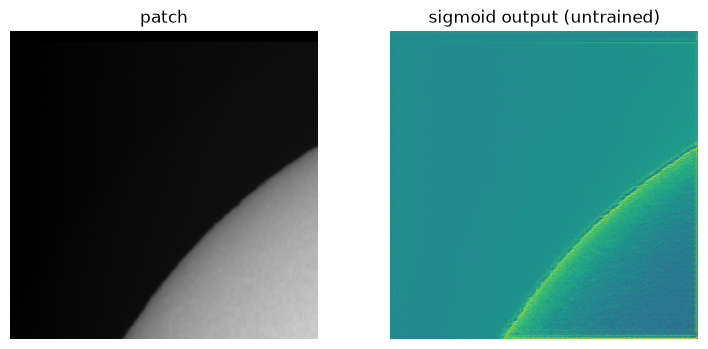

In [10]:
model = build_paper_unet()          # or build_paper_unet(width_scale=0.5) for 2GB-friendly halves
n_params = sum(p.numel() for p in model.parameters())
print(f"PaperUNet params: {n_params / 1e6:.2f}M")

patch = load_fits_patch(EXAMPLE_FITS, 0, 0) / scale
inputs = torch.from_numpy(patch)[None, None]
with torch.no_grad():
    logits = model(inputs)[0, 0]
prob = torch.sigmoid(logits).numpy()
print("logits:", logits.shape, f"outputs>0.5: {(prob > 0.5).sum()} px")

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
axs[0].imshow(patch, cmap="gray", vmin=0, vmax=1); axs[0].set_axis_off(); axs[0].set_title("patch")
axs[1].imshow(prob, cmap="viridis", vmin=0, vmax=1); axs[1].set_axis_off(); axs[1].set_title("sigmoid output (untrained)")

## Next steps
- validate visually on images from different months (spot-free vs big AR days)
- for manual editing: open `OUT_DIR` PNGs in napari/gimp, fix, then move them into
  `$SUNSCC_DATA_ROOT/validation_masks/` (training picks them up as validation set)
- real training: `uv run sunscc-train trainer=mx550 data.batch_size=1`
- evaluation of a saved checkpoint: `uv run sunscc-predict --checkpoint ... --image ... --output ...`
